# Binning

In [27]:
import pandas as pd

df = pd.read_csv('IPL_Matches_tail_300.csv')
df.head()

,Unnamed: 0.1,Unnamed: 0,date,season,city,venue,team1,team2,toss_winner,toss_decision,team1_runs,team1_wickets,team2_runs,team2_wickets,winner,result_type,win_by_runs,win_by_wickets,player_of_match,match_referee,umpire1,umpire2,tv_umpire,reserve_umpire,overs_limit,team1_players,team2_players,winner_encoded
0,0,0,20-05-2022,2022,Mumbai,"Brabourne Stadium, Mumbai",Chennai Super Kings,Rajasthan Royals,Chennai Super Kings,bat,150.0,6,151.0,5,Rajasthan Royals,complete,0,5,R Ashwin,M Nayyar,CB Gaffaney,NA Patwardhan,YC Barde,PG Pathak,20,"RD Gaikwad, DP Conway, MM Ali, N Jagadeesan, A...","YBK Jaiswal, JC Buttler, SV Samson, D Padikkal...",8
1,1,1,21-05-2022,2022,Mumbai,"Wankhede Stadium, Mumbai",Delhi Capitals,Mumbai Indians,Mumbai Indians,field,159.0,7,160.0,5,Mumbai Indians,complete,0,5,JJ Bumrah,J Srinath,Nitin Menon,Tapan Sharma,HAS Khalid,GR Sadashiv Iyer,20,"PP Shaw, DA Warner, MR Marsh, RR Pant, SN Khan...","Ishan Kishan, RG Sharma, D Brevis, Tilak Varma...",5
2,2,2,22-05-2022,2022,Mumbai,"Wankhede Stadium, Mumbai",Sunrisers Hyderabad,Punjab Kings,Sunrisers Hyderabad,bat,157.0,8,160.0,5,Punjab Kings,complete,0,5,Harpreet Brar,J Srinath,AK Chaudhary,NA Patwardhan,CB Gaffaney,Navdeep Singh,20,"PK Garg, Abhishek Sharma, RA Tripathi, AK Mark...","JM Bairstow, S Dhawan, M Shahrukh Khan, MA Aga...",7
3,3,3,24-05-2022,2022,Kolkata,"Eden Gardens, Kolkata",Rajasthan Royals,Gujarat Titans,Gujarat Titans,field,188.0,6,191.0,3,Gujarat Titans,complete,0,7,DA Miller,M Nayyar,BNJ Oxenford,VK Sharma,MA Gough,J Madanagopal,20,"YBK Jaiswal, JC Buttler, SV Samson, D Padikkal...","WP Saha, Shubman Gill, MS Wade, HH Pandya, DA ...",2
4,4,4,25-05-2022,2022,Kolkata,"Eden Gardens, Kolkata",Royal Challengers Bengaluru,Lucknow Super Giants,Lucknow Super Giants,field,207.0,4,193.0,6,Royal Challengers Bengaluru,complete,14,0,RM Patidar,M Nayyar,J Madanagopal,MA Gough,BNJ Oxenford,VK Sharma,20,"V Kohli, F du Plessis, RM Patidar, GJ Maxwell,...","Q de Kock, KL Rahul, M Vohra, DJ Hooda, MP Sto...",9


In [28]:
x = df[['team1_runs']]
x.head()

,team1_runs
0,150.0
1,159.0
2,157.0
3,188.0
4,207.0


In [32]:
bins = [0 , 120 , 150 , 200 , 250 , df['team1_runs'].max()]
labels = ['poor' , 'average' , 'good' , 'very good' , 'crazy']

df['runs_category'] = pd.cut(
    df['team1_runs'] ,
    bins = bins ,
    labels = labels ,
    include_lowest = True
)

df[['team1_runs' , 'runs_category']].head(10)

,team1_runs,runs_category
0,150.0,average
1,159.0,good
2,157.0,good
3,188.0,good
4,207.0,very good
5,157.0,good
6,130.0,average
7,178.0,good
8,193.0,good
9,191.0,good


In [33]:
df['runs_category'].value_counts()

,count
runs_category,
good,136
very good,103
average,31
crazy,13
poor,10


<Axes: xlabel='team1_runs', ylabel='Count'>

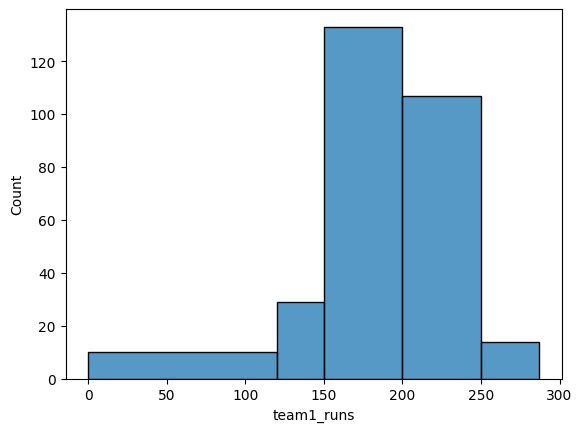

In [35]:

import seaborn as sns

sns.histplot(
    df['team1_runs'],
    bins = bins
)

# Binarizer

In [36]:
import pandas as pd
from sklearn.preprocessing import Binarizer
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('IPLPlayerStat.csv')
df.head()

,Unnamed: 0.1,Unnamed: 0,player,runs,boundaries,balls_faced,wickets,balls_bowled,runs_conceded,matches,batting_avg,batting_strike_rate,boundaries_percent,bowling_economy,bowling_avg,bowling_strike_rate,catches,stumpings,player_form,player_form_encoded
0,0,0,A Ashish Reddy,280,31,196,NaN,270,400,28,10.00,142.86,15.82,8.89,22.22,15.00,8,0,Poor,0
1,1,1,A Badoni,161,18,139,2.0,12,12,11,14.64,115.83,12.95,6.00,6.00,6.00,8,0,Average,1
2,2,2,A Chandila,4,0,7,11.0,234,245,12,0.33,57.14,0.00,6.28,22.27,21.27,2,0,Poor,0
3,3,3,A Chopra,53,7,75,0.0,0,0,6,8.83,70.67,9.33,0.00,0.00,0.00,2,0,Poor,0
4,4,4,A Choudhary,25,2,20,5.0,108,144,5,5.00,125.00,10.00,8.00,28.80,21.60,0,0,Poor,0


In [37]:
df['matches'].describe()

,matches
count,605.000000
mean,32.869421
std,42.215050
min,1.000000
25%,6.000000
50%,14.000000
75%,43.000000
max,221.000000


In [48]:
binarizer = Binarizer(
    threshold = 60
)

In [49]:
df['matches_binary'] = binarizer.fit_transform(
    df[['matches']]
)

df[['matches' , 'matches_binary']].head(10)

,matches,matches_binary
0,28,0
1,11,0
2,12,0
3,6,0
4,5,0
5,1,0
6,3,0
7,42,0
8,7,0
9,154,1


In [50]:
df['matches_binary'].value_counts()

,count
matches_binary,
0,491
1,114
